Побудуйте модель лінійної регресії на кількох ознаках.

    Згенеруйте дані за допомогою функції make_regression. Наприклад,

from sklearn.datasets import make_regression
X, y = make_regression(n_samples=2000, n_features=4, noise=10, random_state=42)

    Розділіть дані на навчальну і тестову вибірки (80/20, random_state=42).

    Навчіть модель LinearRegression.

    Виведіть коефіцієнти моделі та R² на тестовій вибірці в таблиці:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [2]:
X, y = make_regression(n_samples=2000, n_features=4, noise=10, random_state=42)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [4]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1600, 4)
(400, 4)
(1600,)
(400,)


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

In [6]:
display(r2)
print(model.coef_)
print(model.intercept_)

0.9937235937421292

[ 3.60774919 46.86286208 91.88467876 39.63648609]
0.04032304016315713


In [7]:
coefficients = model.coef_.tolist()
coefficients.append(model.intercept_)
coefficients.append(r2)
results = pd.DataFrame({
    "Parameter": ["Feature1", "Feature2", "Feature3", "Feature4", "Intercept", "R^2"],
    "Coefficient": coefficients,
})

In [8]:
display(results)

,Parameter,Coefficient
0,Feature1,3.607749
1,Feature2,46.862862
2,Feature3,91.884679
3,Feature4,39.636486
4,Intercept,0.040323
5,R^2,0.993724


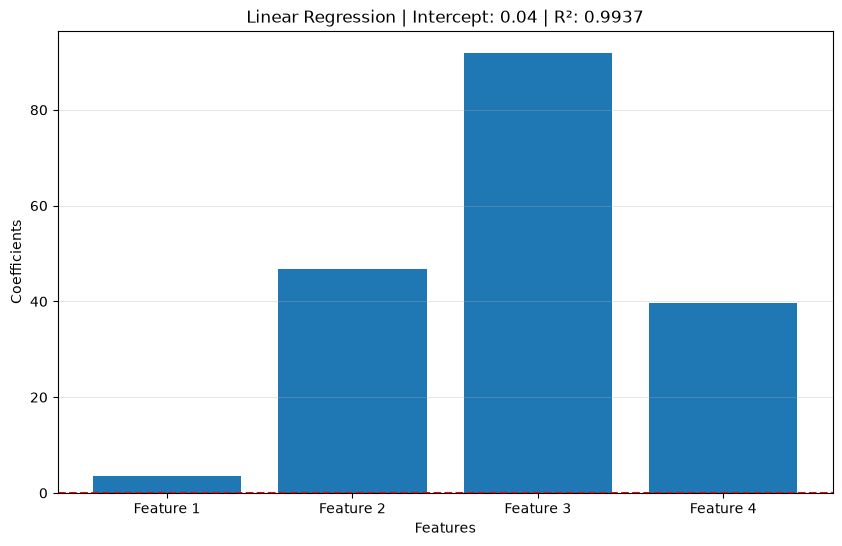

In [9]:
plt.figure(figsize=(10, 6))
plt.bar(
    ["Feature 1", "Feature 2", "Feature 3", "Feature 4"],
    model.coef_
)
plt.axhline(y=0, color="red", linestyle="--")
plt.title(f"Linear Regression | Intercept: {model.intercept_:.2f} | R²: {r2:.4f}")
plt.xlabel("Features")
plt.ylabel("Coefficients")
plt.grid(axis="y", alpha=0.3)
plt.show()

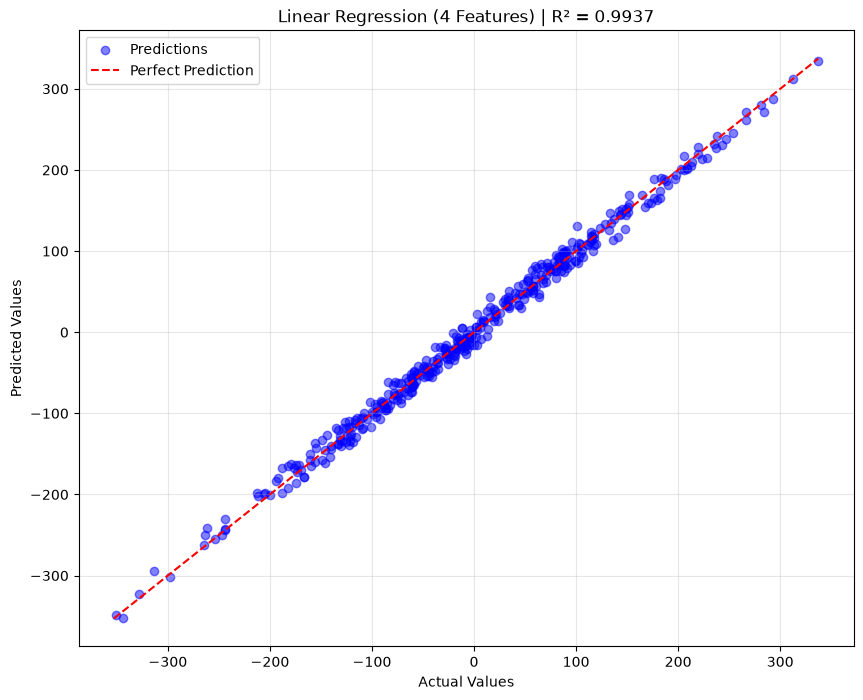

In [10]:
y_pred = model.predict(X_test)
plt.figure(figsize=(10, 8))
plt.scatter(y_test, y_pred, alpha=0.5, color="blue", label="Predictions")

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linestyle="--", label="Perfect Prediction")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title(f"Linear Regression (4 Features) | R² = {r2:.4f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Завдання 2
Перевірте вплив масштабування на роботу лінійної регресії:

    Використовуйте згенеровані дані(make_regression, ті самі параметри).

    Навчіть модель без масштабування і з StandardScaler.

    Порахуйте R² на тестовій вибірці.

    Порівняйте результати в таблиці:

In [11]:
X, y = make_regression(n_samples=2000, n_features=4, noise=10, random_state=42)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [13]:
raw_model = LinearRegression()
raw_model.fit(X_train, y_train)
y_pred = raw_model.predict(X_test)
r2_raw = r2_score(y_test, y_pred)

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
raw_model_scaled = LinearRegression()
raw_model_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = raw_model_scaled.predict(X_test_scaled)
r2_scaled = r2_score(y_test, y_pred_scaled)

In [16]:
results = pd.DataFrame({
    "Model": ["Without Scaling", "With StandardScaler"],
    "R^2": [r2_raw, r2_scaled],
})

In [17]:
display(results)

,Model,R^2
0,Without Scaling,0.993724
1,With StandardScaler,0.993724


Завдання 3
Перевірте, як заповнення пропусків впливає на модель:

    Використовуйте дані make_regression (2000 рядків, 4 ознаки).

    Зробіть частину значень в одній ознаці пропущеними (наприклад, замініть їх на np.nan).

    Заповніть пропуски за допомогою SimpleImputer (середнім значенням).

    Навчіть модель лінійної регресії та порахуйте R².

    Виведіть результат у таблиці:

In [18]:
X, y = make_regression(n_samples=2000, n_features=4, noise=10, random_state=42)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [20]:
rng = np.random.default_rng(42)
mask_trainX = rng.random(X_train.shape[0]) < 0.15
X_train[mask_trainX, 0] = np.nan
maskX_test = rng.random(X_test.shape[0]) < 0.15
X_test[maskX_test, 0] = np.nan

In [27]:
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

model_imputer = LinearRegression()
model_imputer.fit(X_train, y_train)
y_pred_imputer = model_imputer.predict(X_test)
r2_imputer = r2_score(y_test, y_pred_imputer)

In [28]:
results = pd.DataFrame({
    "Model": ["Without scaler", "With scaler", "With imputer"],
    "R^2": [r2_raw, r2_scaled, r2_imputer],
})

In [29]:
display(results)

,Model,R^2
0,Without scaler,0.993724
1,With scaler,0.993724
2,With imputer,0.993731


In [34]:
# TASK 4
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

X, y = make_regression(
    n_samples=2000, n_features=4, noise=10, random_state=42
)
pipeline = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)
scores = cross_val_score(pipeline, X, y, cv=5, scoring="r2")

mean_r2 = np.mean(scores)
std_r2 = np.std(scores)

In [46]:
results = pd.DataFrame({
    "Model": ["Without scaler", "With scaler", "With imputer", "CrossVal mean r2"],
    "R^2": [r2_raw, r2_scaled, r2_imputer, mean_r2],
    "Std R^2": [None, None, None, std_r2],
})
display(results)

,Model,R^2,Std R^2
0,Without scaler,0.993724,NaN
1,With scaler,0.993724,NaN
2,With imputer,0.993731,NaN
3,CrossVal mean r2,0.992122,0.000517
